# Exercitiul 2

### a) Graful si vecinii
Am ales $n=4$ statii meteo asezate in linie, formand un lant: `S1 --- S2 --- S3 --- S4`.
* Vecinii sunt: 
  * S1 are vecin pe S2.
  * S2 are vecini pe S1 si S3.
  * S3 are vecini pe S2 si S4.
  * S4 are vecin pe S3.
* Graful ales este un arbore simplu si nu contine cicluri (nu exista niciun drum care sa se inchida ca o bucla).

### c) Formula distributiei comune
Formula distributiei comune inmulteste toti factorii unari (statiile independente) cu factorii pereche (muchiile dintre ele):
$P(s_1, s_2, s_3, s_4) = \frac{1}{Z} \cdot \phi_1(s_1) \cdot \phi_2(s_2) \cdot \phi_3(s_3) \cdot \phi_4(s_4) \cdot \phi_{12}(s_1, s_2) \cdot \phi_{23}(s_2, s_3) \cdot \phi_{34}(s_3, s_4)$

### e) MAP comun vs. MAP marginal (Comparatie)
Cele doua metode nu coincid intotdeauna:
* **MAP marginal** alege starea optima pentru o singura statie, privita izolat, dupa ce face suma pe restul variabilelor (practic "uita" de restul retelei).
* **MAP comun** cauta combinatia in care absolut toate statiile necunoscute, luate impreuna, formeaza configuratia cu cel mai mare scor global. 
Se poate intampla ca o configuratie globala sa fie foarte probabila impreuna, dar daca extragem o singura statie din ea si o analizam izolat, alta stare sa aiba o probabilitate marginala mai mare.

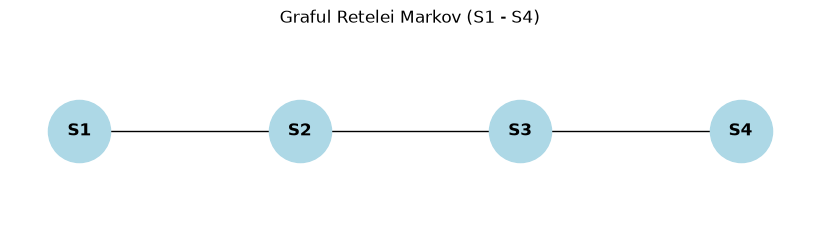

OBSERVATII: La S1 este Soare (0) si la S4 este Ploaie (1)

d) Distributia marginala pentru S2:
+-------+-----------+
| S2    |   phi(S2) |
+=======+===========+
| S2(0) |    0.7903 |
+-------+-----------+
| S2(1) |    0.1694 |
+-------+-----------+
| S2(2) |    0.0403 |
+-------+-----------+

d) Distributia marginala pentru S3:
+-------+-----------+
| S3    |   phi(S3) |
+=======+===========+
| S3(0) |    0.5222 |
+-------+-----------+
| S3(1) |    0.4065 |
+-------+-----------+
| S3(2) |    0.0714 |
+-------+-----------+

e) Configuratia MAP comuna (S2 si S3 luate impreuna):
{'S3': 0, 'S2': 0}


In [2]:
from pgmpy.models import DiscreteMarkovNetwork
from pgmpy.factors.discrete import DiscreteFactor
from pgmpy.inference import BeliefPropagation

import networkx as nx
import matplotlib.pyplot as plt

# b) Construim modelul si factorii 
# Definim un lant de 4 statii
model = DiscreteMarkovNetwork([('S1', 'S2'), ('S2', 'S3'), ('S3', 'S4')])

# Extragem graful intr-un format standard networkx
G = nx.Graph(model.edges())

# Setam pozitiile manual ca sa apara frumos in linie orizontala
pozitii = {'S1': (0, 0), 'S2': (1, 0), 'S3': (2, 0), 'S4': (3, 0)}

# Desenam graful
plt.figure(figsize=(8, 2))
nx.draw(G, pos=pozitii, with_labels=True, node_color='lightblue', node_size=2000, font_weight='bold')
plt.title("Graful Retelei Markov (S1 - S4)")
plt.show()

# Probabilitatile initiale (Soare=0.5, Ploaie=0.3, Nori=0.2)
p_init = [0.5, 0.3, 0.2]

# Adaugam factorii unari pentru fiecare statie
f1 = DiscreteFactor(['S1'], cardinality=[3], values=p_init)
f2 = DiscreteFactor(['S2'], cardinality=[3], values=p_init)
f3 = DiscreteFactor(['S3'], cardinality=[3], values=p_init)
f4 = DiscreteFactor(['S4'], cardinality=[3], values=p_init)

# Matricea Psi pentru factorii pereche, citita rand cu rand
psi_val = [0.7, 0.2, 0.1, 
           0.2, 0.6, 0.2, 
           0.1, 0.3, 0.6]

# Adaugam factorii pereche pentru muchii
f12 = DiscreteFactor(['S1', 'S2'], cardinality=[3, 3], values=psi_val)
f23 = DiscreteFactor(['S2', 'S3'], cardinality=[3, 3], values=psi_val)
f34 = DiscreteFactor(['S3', 'S4'], cardinality=[3, 3], values=psi_val)

model.add_factors(f1, f2, f3, f4, f12, f23, f34)
model.check_model()

infer = BeliefPropagation(model)

print("OBSERVATII: La S1 este Soare (0) si la S4 este Ploaie (1)")

# d) Distributia marginala la statiile neobservate (S2 si S3) 
marg_s2 = infer.query(['S2'], evidence={'S1': 0, 'S4': 1}, show_progress=False)
print("\nd) Distributia marginala pentru S2:")
print(marg_s2)
# Starea cu probabilitatea cea mai mare de aici este MAP marginal pentru S2

marg_s3 = infer.query(['S3'], evidence={'S1': 0, 'S4': 1}, show_progress=False)
print("\nd) Distributia marginala pentru S3:")
print(marg_s3)
# Starea cu probabilitatea cea mai mare de aici este MAP marginal pentru S3

# e) MAP comun pentru toate statiile neobservate 
map_comun = infer.map_query(['S2', 'S3'], evidence={'S1': 0, 'S4': 1}, show_progress=False)
print("\ne) Configuratia MAP comuna (S2 si S3 luate impreuna):")
print(map_comun)